# 현실의 데이터 16: 공유 자전거 수요 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/16_bike_demand.ipynb)

**분야**: 도시 · 공간 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 수요예측 · 모빌리티 · 공유 서비스 · 재배치 운영

> 서울 공유 자전거 1년치 시간별 대여 수. 내일 아침 8시엔 몇 대가 필요할까?

**데이터**: Seoul Bike Sharing Demand (약 0.6MB). UCI (Sathishkumar V E & Cho, 2020), 서울 공공자전거 2017.12~2018.11 시간별 대여 수 8,760개 + 날씨.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 한 시간 |
| ② 입력 X | 시각 · 요일 · 기온 · 습도 · 비 · 휴일 … |
| ③ 출력 y | 그 시간의 대여 수 |
| ④ 평가지표 | MAE (대) |
| ⑤ 기준선 | 학습 기간의 '같은 시각' 평균 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Sathishkumar V E, Park & Cho (2020) Using data mining techniques for bike sharing demand prediction in metropolitan city, Computer Communications](https://doi.org/10.1016/j.comcom.2020.02.007)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
URL = "https://archive.ics.uci.edu/static/public/560/seoul+bike+sharing+demand.zip"
with zipfile.ZipFile(download(URL, "data/seoul_bike.zip")) as z:
    df = pd.read_csv(z.open("SeoulBikeData.csv"), encoding="latin1")
df.columns = ["date", "count", "hour", "temp", "humidity", "wind", "visibility", "dew_point", "solar", "rain", "snow", "season", "holiday", "functioning"]
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")
print(df.shape, df["date"].min().date(), "~", df["date"].max().date())
df.head()

(8760, 14) 2017-12-01 ~ 2018-11-30


,date,count,hour,temp,humidity,wind,visibility,dew_point,solar,rain,snow,season,holiday,functioning
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## 열어 보기

하루 중 언제 많이 빌릴까? 출근 · 퇴근 시간이 보일까?

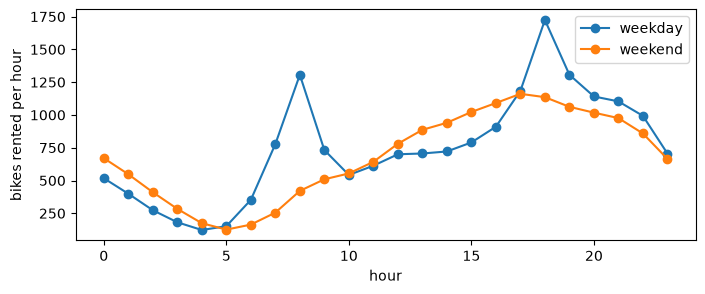

hours when the service was off: 295 (count is always 0 )


In [3]:
df["weekend"] = df["date"].dt.dayofweek >= 5
by_hour = df[df["functioning"] == "Yes"].groupby(["hour", "weekend"])["count"].mean().unstack()
by_hour.columns = ["weekday", "weekend"]
by_hour.plot(figsize=(8, 3), marker="o"); plt.ylabel("bikes rented per hour"); plt.show()
print("hours when the service was off:", (df["functioning"] == "No").sum(), "(count is always", df.loc[df["functioning"] == "No", "count"].max(), ")")

## 문제 하나 골라 보기: 한 시간 → 대여 수

**시간 순서** 로 나눈다: 2018년 9월 전까지 학습, 9~11월 시험. 기준선 = 학습 기간의 같은 시각 (평일/주말 따로) 평균.

In [4]:
from sklearn.ensemble import HistGradientBoostingRegressor

def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))

data = df[df["functioning"] == "Yes"].copy()
data["dow"] = data["date"].dt.dayofweek
train, test = data[data["date"] < "2018-09-01"], data[data["date"] >= "2018-09-01"]
hour_mean = train.groupby(["hour", "weekend"])["count"].mean()
base = test.set_index(["hour", "weekend"]).index.map(hour_mean).values
feats = ["hour", "dow", "temp", "humidity", "wind", "visibility", "solar", "rain", "snow"]
m = HistGradientBoostingRegressor(random_state=0).fit(train[feats], train["count"])
print(f"baseline (same hour mean): MAE {mae(test['count'], base):.0f} bikes")
print(f"gradient boosting        : MAE {mae(test['count'], m.predict(test[feats])):.0f} bikes")

baseline (same hour mean): MAE 355 bikes
gradient boosting        : MAE 234 bikes


**생각해 보기**: 내일 아침 8시를 예측할 때 '내일 8시의 실제 기온 · 강수량' 을 알 수 있을까? 실제 서비스에서는 **일기예보** 를 입력으로 써야 한다. 이 노트북의 점수는 그래서 실제보다 좋게 나온다.

## 다른 문제로 바꿔 보기

- **재배치 운영**: 서울 전체가 아니라 '대여소 × 시간' 을 한 행으로 하면 '어느 대여소에 자전거를 옮겨 둘까' 문제가 된다.
- 비 오는 날을 많이 틀리는 게 더 손해라면 지표를 어떻게 바꿀까?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |